In [1]:
# Notebooks live in Notebooks/GRUMish/, but every data path is relative to the repo root.
import os, sys
while not os.path.isdir("data") and os.getcwd() != "/":
    os.chdir("..")
for p in [os.getcwd(), os.path.join(os.getcwd(), "Notebooks", "GRUMish")]:
    if p not in sys.path:
        sys.path.insert(0, p)
print("cwd:", os.getcwd())

cwd: /home/user1/WhatDoLLMsWant


# 07 — The B matrix of every model (2026-11-03)

In the GRUM, $U(z \mid x) = (a + B^\top x)^\top z$. With one request ("I prefer level ℓ"), x has a single 1, so the
contract adds **one row of B** to the weights: row ℓ of B = the weights under that request − the weights with no
contract.

**How to read one heatmap (11 × 11):**
- **row** = the request (what the user asked for); **column** = the weight that changes (which level of which feature);
- **diagonal blocks** (request on RAM, column in RAM) = the push ρ and the erase σ of notebook 02;
- **off-diagonal blocks** = leakage: what a RAM request does to the brand weights, and so on;
- orange = the weight falls, blue = it rises. The colour scale is **log-like** (linear inside ±1, then logarithmic), so the
  small leakage cells stay visible next to the big push cells; the numbers are exact.

**Two heatmaps per model:**
- **measured** — straight from the runs (one row per single-request run; white = no run for that request);
- **GRUM** — the B implied by the structured GRUM (σ, ρ per feature, κ per pair of features; ideal-point push for
  screen and RAM, peak for brand), fitted on **all** that model's single runs. It also fills rows that were never run,
  as long as the feature was asked at least once. A feature **never** requested in that model's runs leaves its rows at
  their start value, 0 (hatched): no comparison was ever made under such a request, so nothing moves them — like a BT
  weight for an item that is in no pair.

In [2]:
from grumish import *
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, SymLogNorm
setup_plots()
FIG = "figs/GRUMish"
R = load_all()
DIV = LinearSegmentedColormap.from_list("div", [ORANGE, "#f0efec", BLUE]); DIV.set_bad("white")
LAB = [l.replace("-inch", '"') for _, l in LV]

def B_measured(m):
    a = R[(m, "none")].w
    return pd.DataFrame([(R[(m, f"{f}={l}")].w - a).values if (m, f"{f}={l}") in R else np.full(len(LV), np.nan) for f, l in LV],
                        index=pd.MultiIndex.from_tuples(LV), columns=pd.MultiIndex.from_tuples(LV))

def B_grum(m):
    a = R[(m, "none")].w
    singles = [(f, l, R[(m, f"{f}={l}")].w) for f, l in LV if (m, f"{f}={l}") in R]
    P = fit_struct(a, singles)
    rows, unl = [], []
    for f, l in LV:
        ok = f in P["rho"] and all((f, g) in P["kappa"] for g in FEATS if g != f)
        rows.append((predict_struct(a, P, {f: l}) - a).values if ok else np.zeros(len(LV)))   # not learned: stays at its start value, 0
        unl.append(not ok)
    return pd.DataFrame(rows, index=pd.MultiIndex.from_tuples(LV), columns=pd.MultiIndex.from_tuples(LV)), P, np.array(unl)

def draw(ax, Bm, vmax, title, unlearned=None):
    im = ax.imshow(np.ma.masked_invalid(Bm.values), cmap=DIV, norm=SymLogNorm(linthresh=1, vmin=-vmax, vmax=vmax), aspect="equal")
    for i in range(11):
        for j in range(11):
            v = Bm.values[i, j]
            if np.isnan(v) or (unlearned is not None and unlearned[i]): continue
            ax.text(j, i, f"{v:+.0f}" if abs(v) >= 9.5 else f"{v:+.1f}", ha="center", va="center", fontsize=6.3,
                    color="white" if abs(v) > 8 else INK)
    if unlearned is not None:
        for i in np.where(unlearned)[0]:
            ax.add_patch(plt.Rectangle((-0.5, i - 0.5), 11, 1, fill=False, hatch="///", edgecolor=GRAY, lw=0))
        if unlearned.any():
            i0 = np.where(unlearned)[0]
            ax.text(5, i0.mean(), "not learned: no request on this feature in the data (stays 0)", ha="center", va="center",
                    fontsize=8, color=INK, bbox=dict(facecolor="white", edgecolor=GRAY, boxstyle="round,pad=0.3"))
    for b in (4.5, 7.5):
        ax.axhline(b, color=INK2, lw=1); ax.axvline(b, color=INK2, lw=1)
    ax.set_xticks(range(11), LAB, rotation=90, fontsize=8); ax.set_yticks(range(11), [f"ask {x}" for x in LAB], fontsize=8)
    ax.tick_params(length=0); [sp.set_visible(False) for sp in ax.spines.values()]
    ax.set_title(title, loc="left", fontsize=10)
    return im

SUM = []
def show(m):
    Bm, (Bg, P, U) = B_measured(m), B_grum(m)
    vmax = np.nanmax(np.abs(np.r_[Bm.values.ravel(), Bg.values.ravel()]))
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.9))
    draw(axes[0], Bm, vmax, f"measured  ({int(Bm.notna().all(axis=1).sum())} of 11 rows run)")
    im = draw(axes[1], Bg, vmax, f"GRUM  ({int((~U).sum())} of 11 rows learned)", U)
    cb = fig.colorbar(im, ax=axes, shrink=0.7, pad=0.02); cb.set_label("change of the weight (log-odds)"); cb.outline.set_visible(False)
    fig.suptitle(f"{m}: B, one row per request (rows = what was asked, columns = which weight moves)", x=0.01, y=0.93, ha="left", fontsize=11)
    fig.savefig(f"{FIG}/07_B_{m}.png", dpi=150, bbox_inches="tight"); plt.show()
    both = Bm.notna().all(axis=1) & pd.Series(~U, index=Bm.index)
    diag = np.array([[f == g for g, _ in LV] for f, _ in LV])[both.values]
    om, og = Bm.values[both.values], Bg.values[both.values]
    SUM.append(dict(model=m, rows_run=int(Bm.notna().all(axis=1).sum()), rows_grum=int((~U).sum()),
                    r2_all=r2(og.ravel(), om.ravel()), r2_leak=r2(og[~diag], om[~diag]),
                    biggest_leak=float(np.nanmax(np.abs(np.where(np.array([[f == g for g, _ in LV] for f, _ in LV]), np.nan, Bm.values))))))

## qwen

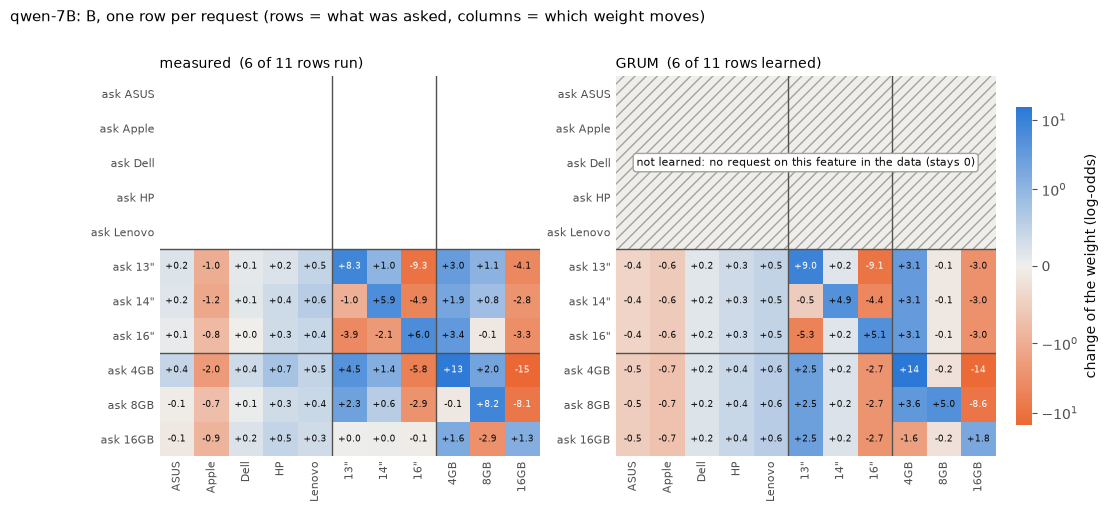

In [3]:
show("qwen-7B")

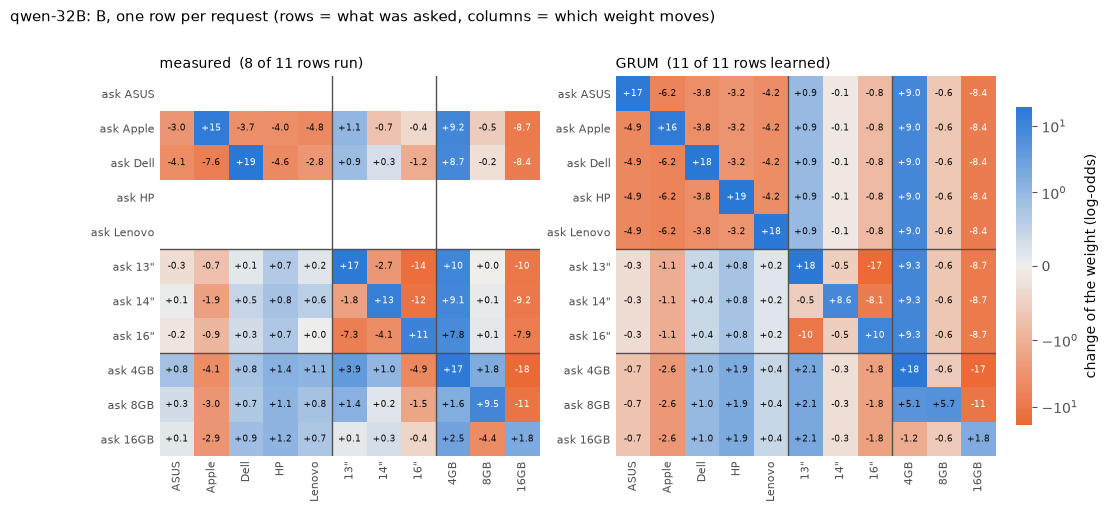

In [4]:
show("qwen-32B")

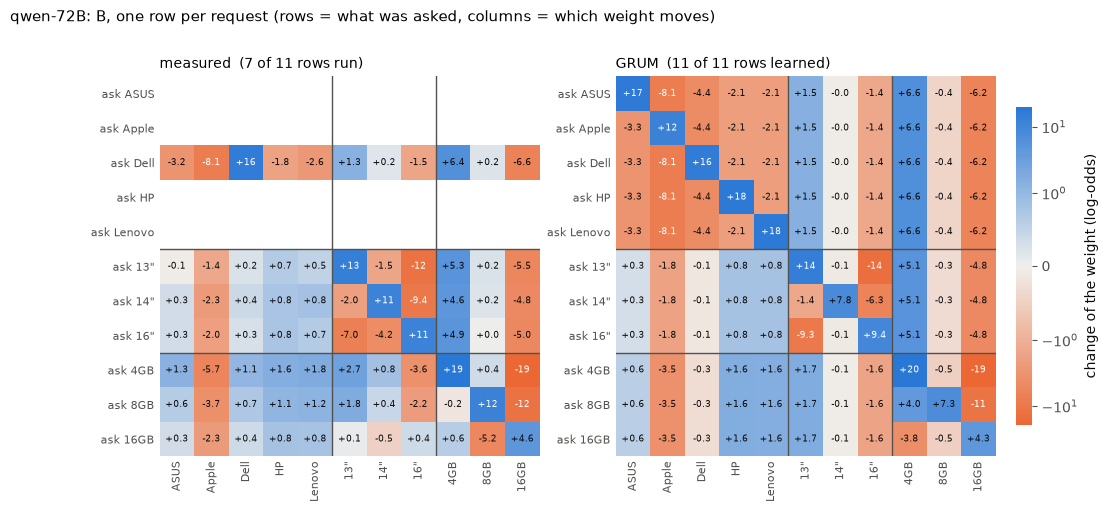

In [5]:
show("qwen-72B")

- **The biggest leakage is not into brand — it is into RAM.** Any screen or brand request pulls the RAM columns toward 0
  (4GB up, 16GB down by 8–10 log-odds): qwen-32B keeps only **49%** of its RAM range under a screen request and **50%**
  under a brand request (qwen-72B 61% / 49%, qwen-7B 77%). The requested feature takes over pairs that RAM used to decide.
- **The Apple column** is negative in every spec row (−3.3 under RAM requests, −1.2 under screen requests, qwen-32B).
- **Brand rows (32B, 72B): a push of +16 … +19 on the requested brand**, and every other brand down by 3–8.
- **`ask 4GB` is the odd row**: it also turns the screen taste (16" −4.9, 13" +3.9 in qwen-32B) — the "budget" turn.
- **GRUM** reproduces the measured B well (R² 0.90 / 0.95 / 0.93), and **fills the 3 brand rows never run** (ASUS, HP,
  Lenovo) with the same push and leakage as Apple and Dell. Its leakage rows are identical inside a block (one κ per
  pair of features), so it cannot show the `4GB` row's extra turn.

## gemma

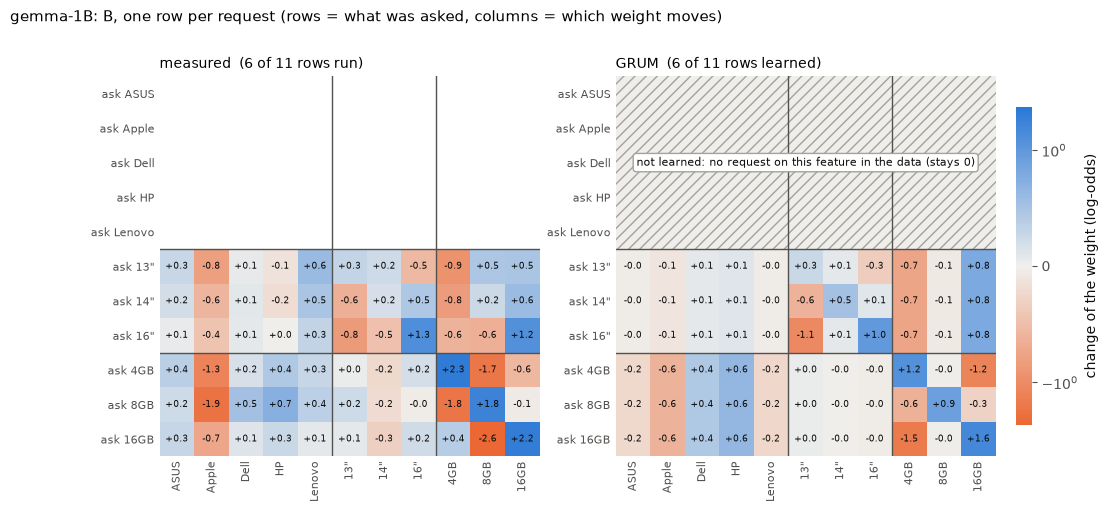

In [6]:
show("gemma-1B")

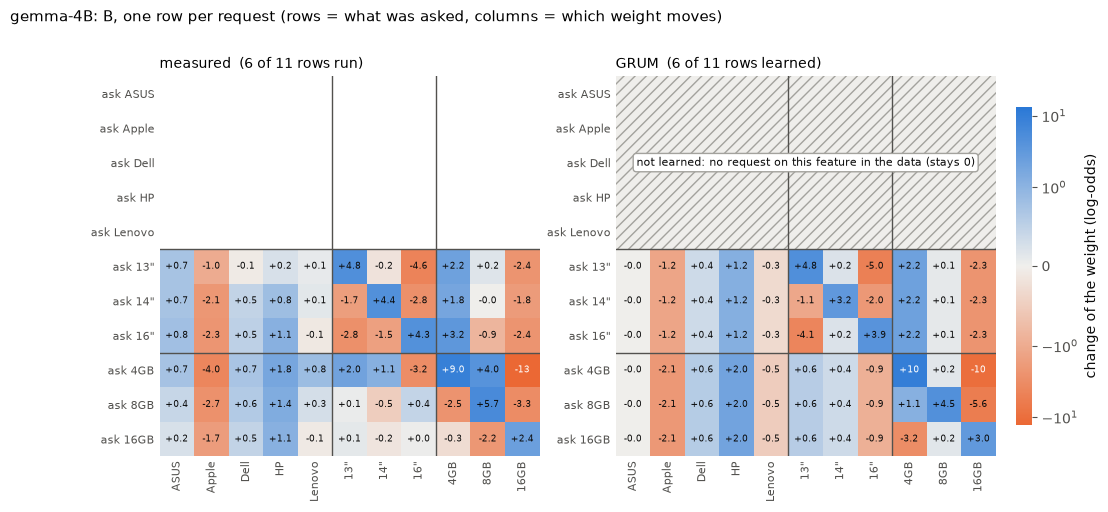

In [7]:
show("gemma-4B")

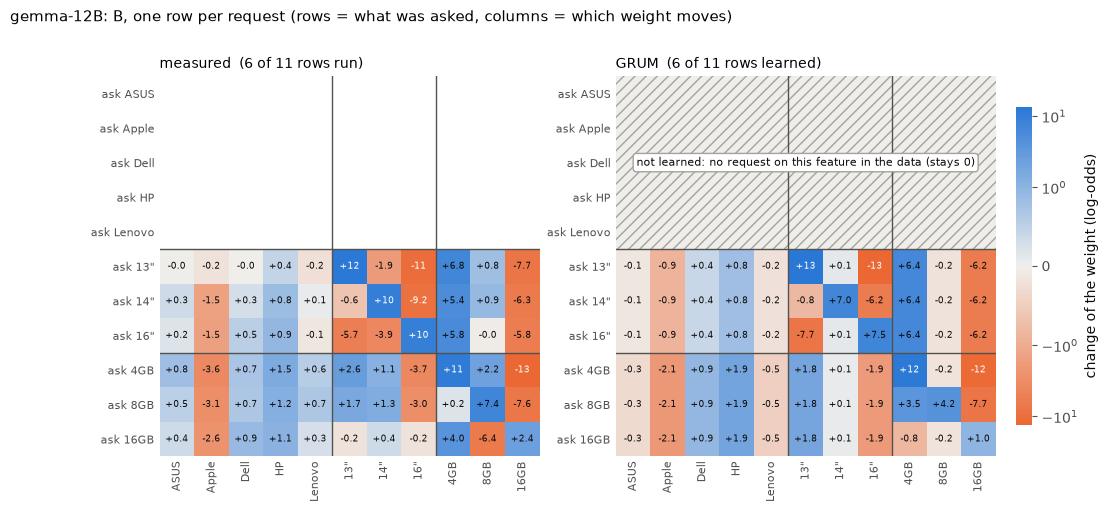

In [8]:
show("gemma-12B")

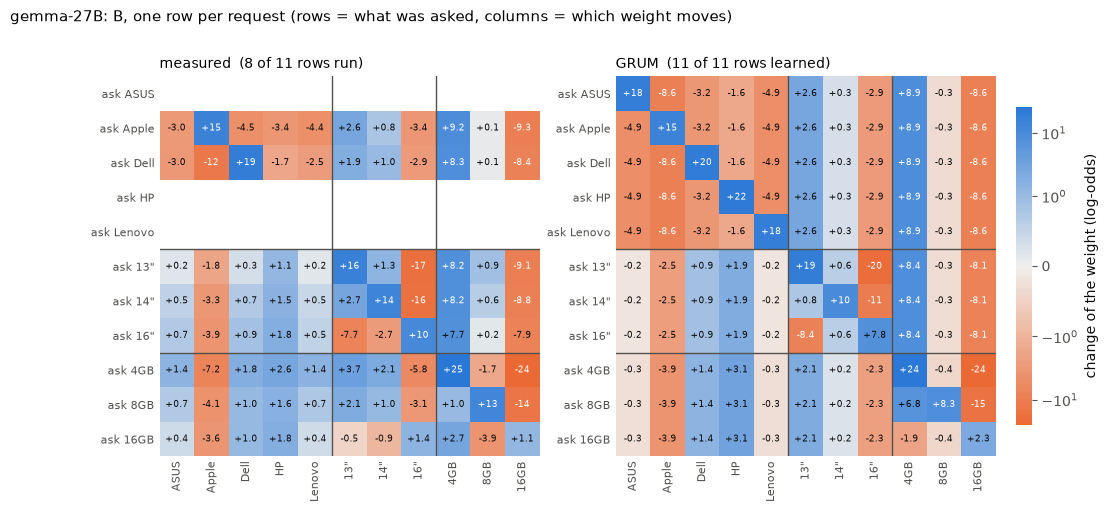

In [9]:
show("gemma-27B")

- **gemma-27B looks almost exactly like qwen-32B** — now also on brand (new runs): push +17 on the requested brand,
  RAM range kept 43% under a brand request, 46% under a screen request; Apple −5.0 under RAM requests (the biggest of
  all models), −7.2 under `4GB`. GRUM R² 0.94.
- **gemma-12B and gemma-4B** have the same pattern, weaker (RAM kept 51% / 85% under screen requests). GRUM R² 0.87 / 0.82.
- **gemma-1B barely reacts**: the diagonal pushes are small and the off-diagonal cells are noise (GRUM R² 0.43); a screen
  request does not even flatten RAM (110% kept).

## OLMo

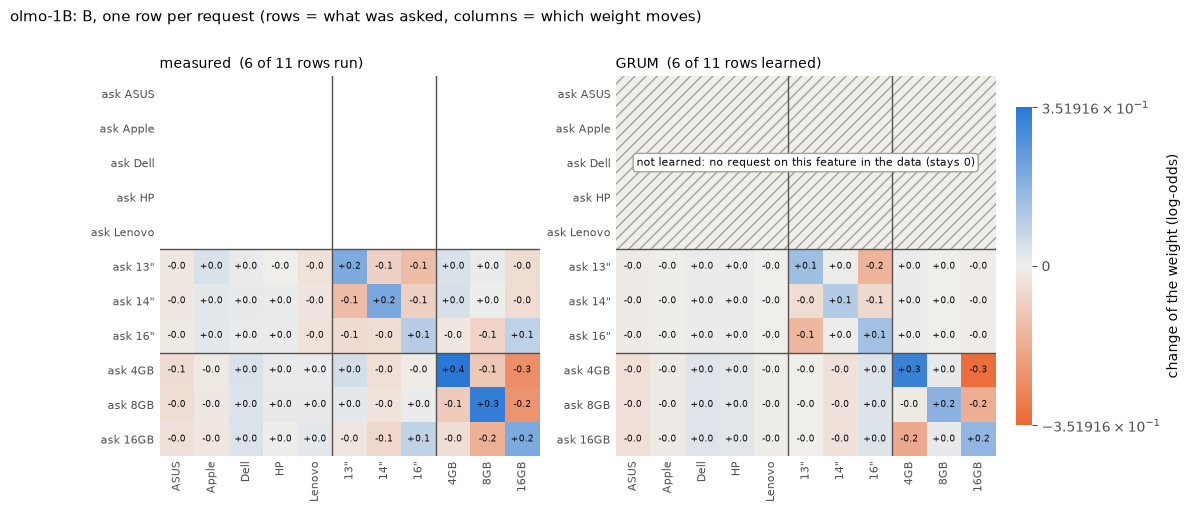

In [10]:
show("olmo-1B")

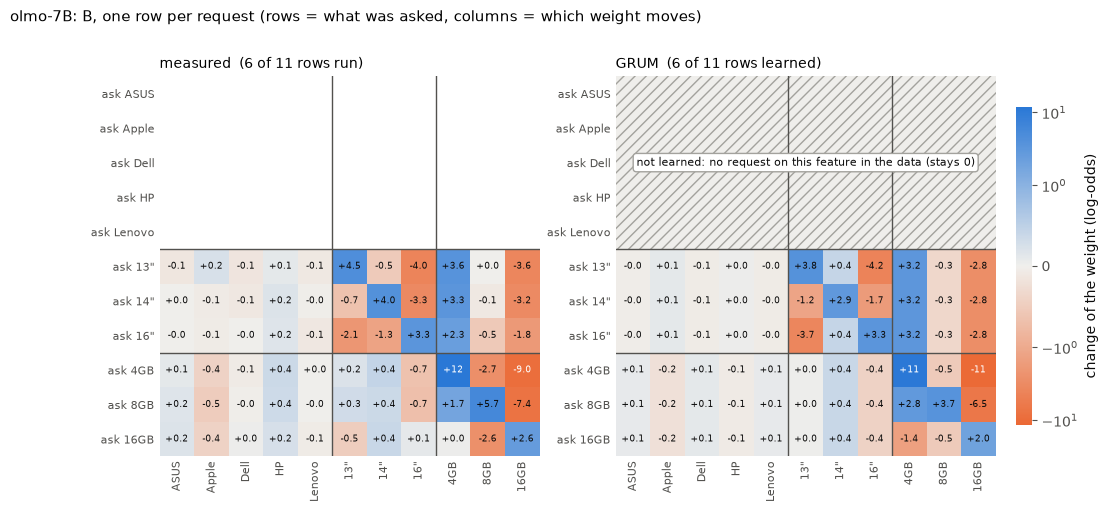

In [11]:
show("olmo-7B")

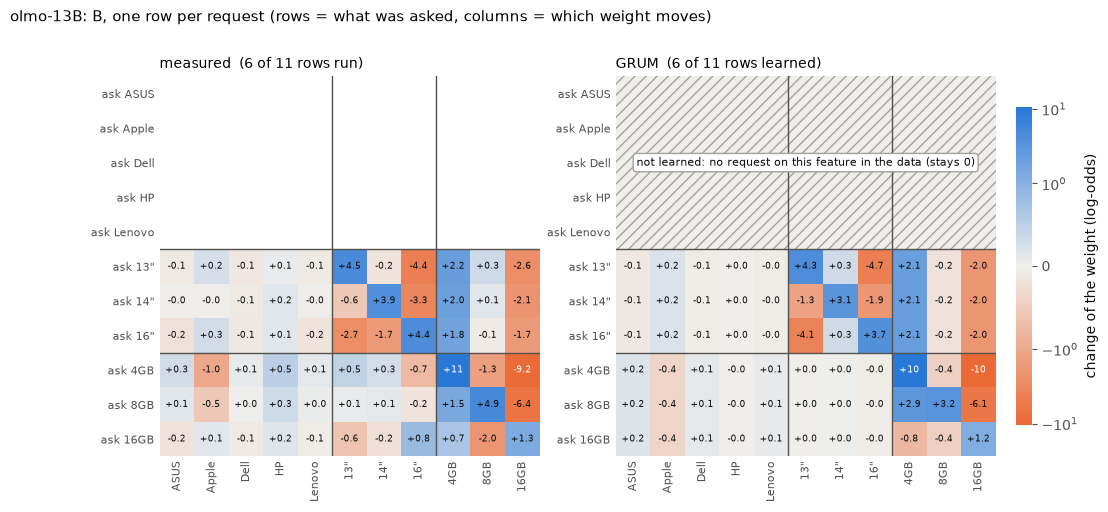

In [12]:
show("olmo-13B")

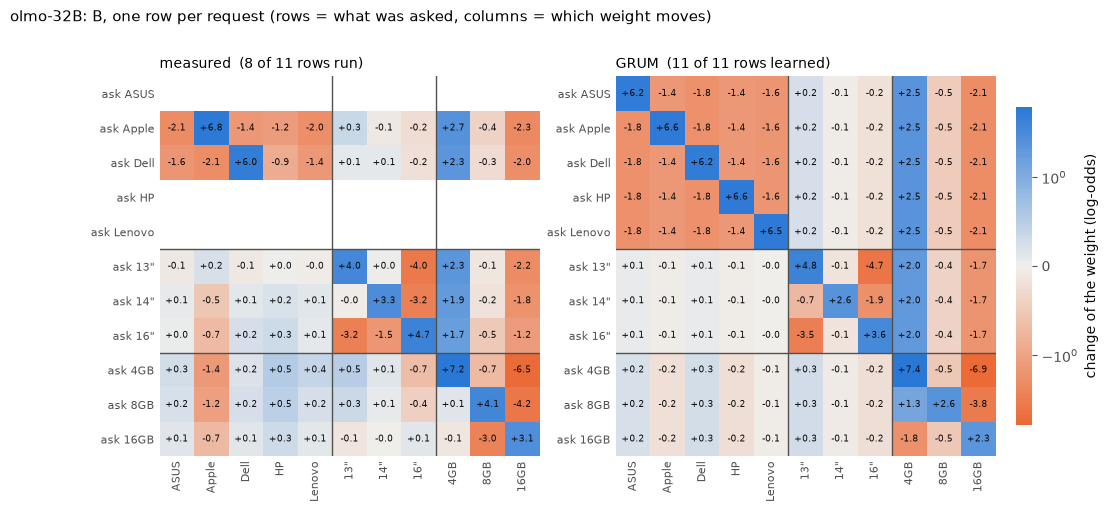

In [13]:
show("olmo-32B")

- **New: OLMo Phase A and brand runs landed** (11-03), so OLMo now has 6 (8 for 32B) rows per model.
- **Same structure, much smaller scale**: diagonal pushes of +3 … +7 (vs +10 … +25 in qwen/gemma), because OLMo's tastes
  are small (RAM range 8–15, screen < 1).
- **Brand rows (olmo-32B)**: push +6.4 on the requested brand, RAM range kept 45% — the same priority shift as qwen and
  gemma.
- **Almost no Apple decay**: Apple −0.4 … −1.1 under RAM requests, ~0 under screen requests. OLMo has no Apple taste to
  lose, which fits "the decay is shrinkage of the favourite".
- olmo-1B is noise (scale < 1). GRUM R² 0.92 / 0.94 / 0.93 for olmo-7B / 13B / 32B.

## Summary over models

How close is the GRUM's B to the measured one, on the rows that have a run? R² over all cells, and over the leakage cells only (off-diagonal blocks).

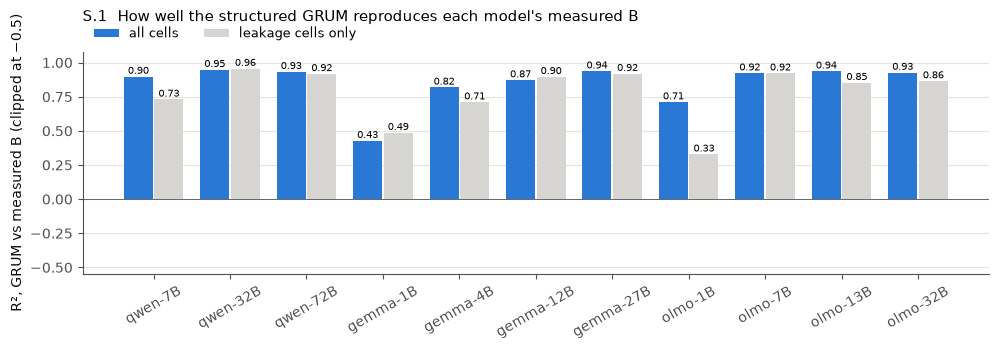

           rows_run  rows_grum  r2_all  r2_leak  biggest_leak
model                                                        
qwen-7B           6          6    0.90     0.73          5.84
qwen-32B          8         11    0.95     0.96         10.04
qwen-72B          7         11    0.93     0.92          6.56
gemma-1B          6          6    0.43     0.49          1.85
gemma-4B          6          6    0.82     0.71          4.04
gemma-12B         6          6    0.87     0.90          7.66
gemma-27B         8         11    0.94     0.92          9.31
olmo-1B           6          6    0.71     0.33          0.09
olmo-7B           6          6    0.92     0.92          3.63
olmo-13B          6          6    0.94     0.85          2.57
olmo-32B          8         11    0.93     0.86          2.68


In [14]:
SM = pd.DataFrame(SUM).set_index("model")
fig, ax = plt.subplots(figsize=(10, 3.6))
x = np.arange(len(SM))
ax.bar(x - 0.2, SM.r2_all.clip(lower=-0.5), 0.38, color=BLUE, label="all cells")
ax.bar(x + 0.2, SM.r2_leak.clip(lower=-0.5), 0.38, color=LGRAY, label="leakage cells only")
for i, (u, v) in enumerate(zip(SM.r2_all, SM.r2_leak)):
    ax.text(i - 0.2, max(u, -0.5) + 0.02, f"{u:.2f}", ha="center", fontsize=7.5); ax.text(i + 0.2, max(v, -0.5) + 0.02, f"{v:.2f}", ha="center", fontsize=7.5)
ax.axhline(0, color=INK2, lw=0.6); ax.set_xticks(x, SM.index, rotation=30); ax.set_ylabel("R², GRUM vs measured B (clipped at −0.5)")
ax.set_ylim(-0.55, 1.08); ax.legend(frameon=False, fontsize=9, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_title("S.1  How well the structured GRUM reproduces each model's measured B", loc="left", pad=22)
fig.tight_layout(); fig.savefig(f"{FIG}/07_B_summary.png", dpi=150); plt.show()
print(SM.round(2).to_string())

- **The structured GRUM reproduces the measured B in every model that reacts**: R² 0.82–0.95 over all cells, 0.71–0.96 on
  the leakage cells alone. The two misses are the two models that barely react (gemma-1B 0.43, olmo-1B 0.71).
- **Same picture in all three families**: a big push on the diagonal, the RAM taste flattened by any other request
  (it keeps 43–77% of its range), and the favourite brand falling under spec requests.
- **What the GRUM cannot draw**: leakage that depends on the requested level (the `ask 4GB` row turning the screen, while
  `ask 16GB` leaves it alone). Its leakage rows are identical inside a block, by construction.